# Temporal aggregation results (RQ2)

**Question.** Does learned temporal aggregation (LSTM, Transformer) beat simple pooling of frame scores?

**Setup.** Frame model `vit_b16_full_no-mask_ffpp+celebdf_sbi-none`. Each video is cut into windows of 32 frames
(6 per val/test video). Four aggregators turn a window's 32 frame scores into one window score:

| Aggregator | What it does |
|---|---|
| mean | average of the 32 frame probabilities |
| top-5 | average of the 5 highest frame probabilities |
| LSTM | BiLSTM over the 32 ViT feature vectors, trained on train windows |
| Transformer | 2-layer Transformer encoder over the same features |

A video's score is the mean of its window scores, as in `src.temporal.evaluate`.

**Findings so far** (each is worked through below):

1. On clean video, LSTM and Transformer tie with mean pooling on val: every paired difference is within about
   ±0.002 AUC and every 95% interval includes zero.
2. On DFDC (unseen, test), LSTM and Transformer are about 0.01 AUC *worse* than mean pooling, and the intervals
   exclude zero.
3. The only learned-head win is the Transformer under call quality (about +0.005), the condition affected by the
   per-frame flicker in `degrade()`. It has to be rechecked once the call-quality features are redone.
4. Mean pooling gives the best decision rule on val: it catches the most fakes at ≤1% false alarms and alarms after
   2 windows instead of 3-4.
5. The learned heads fit their training features within two epochs and become overconfident, which explains 1-4.

**Rule.** Every choice is made on val. Test numbers are for reporting only.

**Running it.** On the GPU machine, from the repo root: `jupyter nbconvert --execute --to notebook --inplace
notebooks/temporal_results.ipynb` (or open it in Jupyter). On a laptop, extract
`exports/2026-10-28_temporal_results.tar.gz` (window scores, metrics, decision rules; no videos or crops) in the
repo root, which gives `data/runs/temporal/...`; `/data` is in `.gitignore`, so it is never committed. Elsewhere,
set the `DATA_ROOT` environment variable to the folder that holds `runs/`. Only pandas, numpy, scikit-learn and matplotlib are needed; no GPU.

In [6]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT))
from src.analysis.frames import FAKE, GRID, INK, INK_2, REAL, SERIES, SURFACE  # also sets the figure style

%matplotlib inline

# the repo's data/ folder (git-ignored) if it exists, as on a laptop; otherwise ~/data, as on the GPU machine.
# The DATA_ROOT environment variable overrides both.
DATA_ROOT = Path(os.environ.get("DATA_ROOT") or (ROOT / "data" if (ROOT / "data").exists() else "~/data")).expanduser()
RUN = "no-mask/vit_b16_full_no-mask_ffpp+celebdf_sbi-none"
RUN_DIR = DATA_ROOT / "runs" / "temporal" / RUN
assert RUN_DIR.exists(), f"no temporal run at {RUN_DIR}: set DATA_ROOT"

# aggregator folder -> display name
AGGREGATORS = {"mean": "mean", "topk-5": "top-5", "lstm": "LSTM", "transformer": "Transformer"}
OTHERS = ["top-5", "LSTM", "Transformer"]  # each compared against mean pooling
DATASETS = {"ffpp": "FF++", "celebdf": "Celeb-DF", "dfdc": "DFDC"}
NAMES = ["val", "val_call", "test", "test_call"]  # window-score tables per aggregator

# mean pooling is the reference, so it gets neutral ink; the other three take the first categorical slots,
# which stay distinguishable from each other with colour blindness. Marker shapes repeat the identity.
COLOR = {"mean": INK_2, "top-5": SERIES[0], "LSTM": SERIES[1], "Transformer": SERIES[2]}
MARKER = {"mean": "o", "top-5": "o", "LSTM": "s", "Transformer": "D"}

B, SEED = 2000, 0  # bootstrap resamples and seed

## 1. Data

One row per window, per aggregator. Val and test have up to 6 windows per video; all four aggregators score the
same windows, so the comparison below is paired.

In [7]:
def read_windows(agg: str, name: str) -> pd.DataFrame:
    w = pd.read_csv(RUN_DIR / agg / "predictions" / f"{name}_windows.csv", dtype={"video_id": str})
    return w.assign(aggregator=AGGREGATORS[agg], split=name.split("_")[0],
                    condition="call" if name.endswith("_call") else "clean")


windows = pd.concat([read_windows(a, n) for a in AGGREGATORS for n in NAMES], ignore_index=True)
videos = (windows.groupby(["aggregator", "split", "condition", "video_id"], as_index=False)
          .agg(dataset=("dataset", "first"), method=("method", "first"), label=("label", "first"),
               windows=("score", "size"), score=("score", "mean")))

# the same windows for every aggregator, or the comparison is not paired
counts = windows.groupby(["split", "condition", "aggregator"]).size().unstack("aggregator")
assert (counts.nunique(axis=1) == 1).all(), counts

sizes = (videos[videos.aggregator == "mean"]
         .groupby(["split", "condition", "dataset"])
         .agg(real=("label", lambda s: int((s == 0).sum())), fake=("label", "sum"), windows=("windows", "sum")))
sizes

real  fake  windows
split condition dataset                     
test  call      celebdf   178   340     3082
                dfdc       77   323     2400
                ffpp      140   560     4200
      clean     celebdf   178   340     3082
                dfdc       77   323     2400
                ffpp      140   560     4200
val   call      celebdf   146   297     2635
                ffpp      140   560     4199
      clean     celebdf   146   297     2635
                ffpp      140   560     4199

## 2. Video AUC by aggregator

Recomputed from the window scores and checked against the `*_metrics.json` files the pipeline wrote.

In [8]:
def auc_of(v: pd.DataFrame) -> float:
    return float(roc_auc_score(v.label, v.score))


rows = []
for (split, condition, dataset, agg), v in videos.groupby(["split", "condition", "dataset", "aggregator"]):
    rows.append(dict(split=split, condition=condition, dataset=DATASETS[dataset], aggregator=agg, auc=auc_of(v)))
auc = (pd.DataFrame(rows).pivot(index=["split", "condition", "dataset"], columns="aggregator", values="auc")
       [list(AGGREGATORS.values())].sort_index(level=["split", "condition"], ascending=[False, True]))

# cross-check against the pipeline's own metrics
for agg_dir, agg in AGGREGATORS.items():
    for name in NAMES:
        m = json.loads((RUN_DIR / agg_dir / "predictions" / f"{name}_metrics.json").read_text())
        split, condition = name.split("_")[0], "call" if name.endswith("_call") else "clean"
        for dataset, label in DATASETS.items():
            if dataset in m:
                assert abs(m[dataset]["video_auc"] - auc.loc[(split, condition, label), agg]) < 1e-9

auc.style.format("{:.4f}").highlight_max(axis=1, props="font-weight: bold")

Every row is close. In-domain val and test are near 1 (Celeb-DF is saturated), DFDC is about 0.90. Whether any gap
is real needs the paired comparison in the next section.

## 3. Paired bootstrap: is any aggregator better than mean pooling?

For each aggregator, the difference AUC(aggregator) − AUC(mean pooling) on the same videos. Its 95% interval comes
from resampling videos (real and fake separately, so class sizes stay fixed) 2,000 times and recomputing both AUCs
on each resample. Because both AUCs use the same resampled videos, most of the noise cancels, which makes this much
tighter than comparing two separate intervals. An interval that excludes zero is a real difference on this data.
It does not include seed-to-seed variation of training, since each head was trained once.

In [9]:
def paired_bootstrap(split: str, condition: str, dataset: str | None) -> list[dict]:
    v = videos[(videos.split == split) & (videos.condition == condition)]
    if dataset is not None:
        v = v[v.dataset == dataset]
    scores = v.pivot(index="video_id", columns="aggregator", values="score").dropna()
    y = v.drop_duplicates("video_id").set_index("video_id").label.loc[scores.index].to_numpy()
    s = {a: scores[a].to_numpy() for a in AGGREGATORS.values()}
    real, fake = np.flatnonzero(y == 0), np.flatnonzero(y == 1)

    rng = np.random.default_rng(SEED)
    diffs = np.empty((B, len(OTHERS)))
    for b in range(B):
        i = np.concatenate([rng.choice(real, len(real)), rng.choice(fake, len(fake))])
        base = roc_auc_score(y[i], s["mean"][i])
        diffs[b] = [roc_auc_score(y[i], s[a][i]) - base for a in OTHERS]
    lo, hi = np.percentile(diffs, [2.5, 97.5], axis=0)

    base = roc_auc_score(y, s["mean"])
    return [dict(split=split, condition=condition, dataset=DATASETS.get(dataset, "FF++ + Celeb-DF"),
                 real=len(real), fake=len(fake), aggregator=a, mean_auc=base,
                 diff=roc_auc_score(y, s[a]) - base, lo=lo[j], hi=hi[j])
            for j, a in enumerate(OTHERS)]


CELLS = [("val", c, d) for c in ("clean", "call") for d in (None, "ffpp", "celebdf")] + \
        [("test", c, d) for c in ("clean", "call") for d in ("ffpp", "celebdf", "dfdc")]
boot = pd.DataFrame([r for cell in CELLS for r in paired_bootstrap(*cell)])
boot["excludes_0"] = (boot.lo > 0) | (boot.hi < 0)


def show(t: pd.DataFrame) -> pd.DataFrame:
    cell = lambda r: f"{r['diff']:+.4f} [{r.lo:+.4f}, {r.hi:+.4f}]" + (" *" if r.excludes_0 else "")
    return (t.assign(cell=t.apply(cell, axis=1))
            .pivot(index=["split", "condition", "dataset", "real", "fake"], columns="aggregator", values="cell")
            [OTHERS].sort_index(level=["split", "condition"], ascending=[False, True]))


print("AUC(aggregator) - AUC(mean pooling), 95% paired bootstrap interval; * = excludes 0")
show(boot)

AUC(aggregator) - AUC(mean pooling), 95% paired bootstrap interval; * = excludes 0


aggregator                                                      top-5  \
split condition dataset         real fake                               
val   call      Celeb-DF        146  297   +0.0003 [-0.0022, +0.0034]   
                FF++            140  560   +0.0020 [-0.0025, +0.0064]   
                FF++ + Celeb-DF 286  857   +0.0013 [-0.0011, +0.0041]   
      clean     Celeb-DF        146  297   -0.0002 [-0.0013, +0.0011]   
                FF++            140  560   -0.0010 [-0.0026, +0.0004]   
                FF++ + Celeb-DF 286  857   -0.0006 [-0.0016, +0.0003]   
test  call      Celeb-DF        178  340   +0.0009 [-0.0008, +0.0032]   
                DFDC            77   323   -0.0037 [-0.0120, +0.0034]   
                FF++            140  560   -0.0009 [-0.0036, +0.0018]   
      clean     Celeb-DF        178  340   +0.0004 [-0.0014, +0.0029]   
                DFDC            77   323   -0.0066 [-0.0148, +0.0008]   
                FF++            140  560   -0.0005 [-0.0020, +0.0009]   

aggregator                                                         LSTM  \
split condition dataset         real fake                                 
val   call      Celeb-DF        146  297     +0.0002 [-0.0017, +0.0022]   
                FF++            140  560     +0.0012 [-0.0013, +0.0037]   
                FF++ + Celeb-DF 286  857     +0.0005 [-0.0010, +0.0021]   
      clean     Celeb-DF        146  297     -0.0002 [-0.0011, +0.0006]   
                FF++            140  560     -0.0003 [-0.0024, +0.0019]   
                FF++ + Celeb-DF 286  857     -0.0002 [-0.0014, +0.0011]   
test  call      Celeb-DF        178  340     -0.0005 [-0.0021, +0.0010]   
                DFDC            77   323     -0.0053 [-0.0176, +0.0070]   
                FF++            140  560     -0.0010 [-0.0039, +0.0019]   
      clean     Celeb-DF        178  340     -0.0005 [-0.0020, +0.0013]   
                DFDC            77   323   -0.0111 [-0.0220, -0.0006] *   
                FF++            140  560     +0.0001 [-0.0016, +0.0020]   

aggregator                                                  Transformer  
split condition dataset         real fake                                
val   call      Celeb-DF        146  297     +0.0003 [-0.0020, +0.0030]  
                FF++            140  560   +0.0057 [+0.0014, +0.0103] *  
                FF++ + Celeb-DF 286  857   +0.0039 [+0.0014, +0.0066] *  
      clean     Celeb-DF        146  297     -0.0004 [-0.0018, +0.0009]  
                FF++            140  560     -0.0020 [-0.0045, +0.0003]  
                FF++ + Celeb-DF 286  857     -0.0006 [-0.0022, +0.0008]  
test  call      Celeb-DF        178  340     -0.0003 [-0.0026, +0.0021]  
                DFDC            77   323     -0.0067 [-0.0176, +0.0049]  
                FF++            140  560   +0.0053 [+0.0023, +0.0084] *  
      clean     Celeb-DF        178  340     -0.0003 [-0.0026, +0.0023]  
                DFDC            77   323   -0.0103 [-0.0199, -0.0010] *  
                FF++            140  560     +0.0010 [-0.0007, +0.0026]

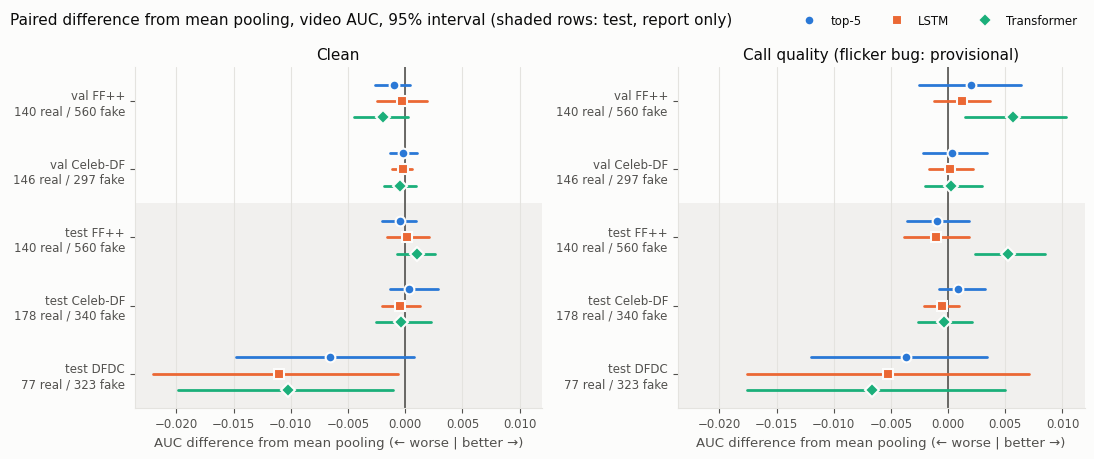

In [10]:
def forest(ax, t: pd.DataFrame, title: str) -> None:
    t = t[t.dataset != "FF++ + Celeb-DF"]  # the pooled val row is in the table; the plot shows each dataset
    labels = t.drop_duplicates(["split", "dataset"])[["split", "dataset", "real", "fake"]].to_numpy()
    for row, (split, dataset, real, fake) in enumerate(labels):
        if split == "test":
            ax.axhspan(row - 0.5, row + 0.5, color=GRID, alpha=0.45, lw=0)
        for j, a in enumerate(OTHERS):
            r = t[(t.split == split) & (t.dataset == dataset) & (t.aggregator == a)].iloc[0]
            y = row + (j - 1) * 0.24
            ax.plot([r.lo, r.hi], [y, y], color=COLOR[a], lw=2, solid_capstyle="round")
            ax.plot(r["diff"], y, MARKER[a], ms=7, color=COLOR[a], mec=SURFACE, mew=1.5, zorder=3,
                    label=a if row == 0 else None)
    ax.axvline(0, color=INK_2, lw=1.2, zorder=1)
    ax.set_yticks(range(len(labels)), [f"{s} {d}\n{r} real / {f} fake" for s, d, r, f in labels])
    ax.set_ylim(len(labels) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set(title=title, xlabel="AUC difference from mean pooling (← worse | better →)")


fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True)
for ax, condition, title in zip(axes, ("clean", "call"), ("Clean", "Call quality (flicker bug: provisional)")):
    forest(ax, boot[boot.condition == condition], title)
axes[1].tick_params(labelleft=True)
fig.suptitle("Paired difference from mean pooling, video AUC, 95% interval (shaded rows: test, report only)",
             x=0.01, ha="left", fontsize=11)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=3, bbox_to_anchor=(0.99, 1.0))
fig.tight_layout()
plt.show()

In [11]:
v = videos[(videos.aggregator == "mean") & (videos.split == "test") & (videos.condition == "clean")
           & (videos.dataset == "dfdc")]
y, s = v.label.to_numpy(), v.score.to_numpy()
real, fake = np.flatnonzero(y == 0), np.flatnonzero(y == 1)
rng = np.random.default_rng(SEED)
resampled = [roc_auc_score(y[i], s[i]) for i in
             (np.concatenate([rng.choice(real, len(real)), rng.choice(fake, len(fake))]) for _ in range(B))]
print(f"DFDC, mean pooling, clean: AUC {roc_auc_score(y, s):.3f} "
      f"[{np.percentile(resampled, 2.5):.3f}, {np.percentile(resampled, 97.5):.3f}] ({len(real)} real, {len(fake)} fake)")

DFDC, mean pooling, clean: AUC 0.907 [0.873, 0.936] (77 real, 323 fake)


**Reading it.**

- **Clean val** (the rows used for the choice): no aggregator differs from mean pooling. All intervals include
  zero and the point estimates are within about 0.002.
- **DFDC clean** (test): LSTM and Transformer are about 0.01 worse than mean pooling and their intervals exclude
  zero. They seem to fit FF++ / Celeb-DF specifics that do not transfer; pooling has nothing to fit. This is a test
  result, so it is reported, not used to choose.
- **Call quality, FF++**: the Transformer is about +0.005 better on both val and test, the only learned-head win.
  The call-quality crops were degraded with settings drawn per frame, so they flicker within a window, which real
  calls do not. The Transformer may have learned to discount the worst-degraded frames of that artificial flicker.
  Recheck after the call-quality fix before reporting it.

## 4. Decision rule

Flag a video once N consecutive windows score at or above a threshold. `src.temporal.decision` picks N ≤ 4 and the
lowest threshold that keeps the val false-alarm rate at or below 1% on clean, call quality and both pooled, then
scores test once. TPR is the share of fake videos flagged; the delay is how many windows it takes.

In [12]:
rules, tests = [], []
for agg_dir, agg in AGGREGATORS.items():
    rule = json.loads((RUN_DIR / agg_dir / "decision.json").read_text())
    rules.append(dict(aggregator=agg, n=rule["n"], threshold=rule["threshold"], one_minus_threshold=1 - rule["threshold"],
                      val_fpr_pooled=rule["val_fpr"]["pooled"], val_tpr_clean=rule["val_tpr"]["clean"],
                      val_tpr_call=rule["val_tpr"]["call"], val_tpr_pooled=rule["val_tpr"]["pooled"]))
    tests.append(pd.read_csv(RUN_DIR / agg_dir / "decision_test.csv").assign(aggregator=agg))
rules = pd.DataFrame(rules).set_index("aggregator")
tests = pd.concat(tests, ignore_index=True)

print("Rule chosen on val")
display(rules.style.format({"threshold": "{:.6f}", "one_minus_threshold": "{:.1e}", "val_fpr_pooled": "{:.3f}",
                            "val_tpr_clean": "{:.3f}", "val_tpr_call": "{:.3f}", "val_tpr_pooled": "{:.3f}"})
        .highlight_max(subset=["val_tpr_clean", "val_tpr_call", "val_tpr_pooled"], props="font-weight: bold"))

print("Test (report only): TPR / FPR per dataset")
test_table = tests.pivot(index=["test_set", "dataset"], columns="aggregator", values=["tpr", "fpr"])
display(test_table.reindex(columns=list(AGGREGATORS.values()), level=1).style.format("{:.3f}"))

Rule chosen on val


,n,threshold,one_minus_threshold,val_fpr_pooled,val_tpr_clean,val_tpr_call,val_tpr_pooled
aggregator,,,,,,,
mean,2,0.922675,7.7e-02,0.007,0.909,0.748,0.828
top-5,4,0.999877,1.2e-04,0.007,0.881,0.743,0.812
LSTM,3,0.999926,7.4e-05,0.005,0.830,0.679,0.754
Transformer,4,0.999956,4.4e-05,0.007,0.867,0.714,0.791


Test (report only): TPR / FPR per dataset


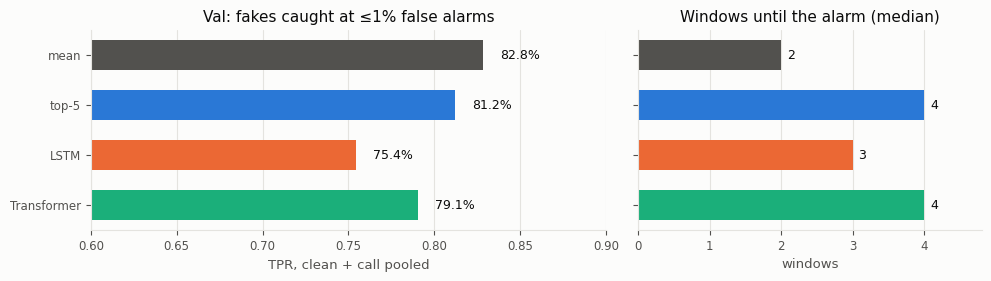

In [13]:
fig, (ax_tpr, ax_delay) = plt.subplots(1, 2, figsize=(10, 2.9), gridspec_kw=dict(width_ratios=[3, 2]))
names = list(AGGREGATORS.values())
y = np.arange(len(names))
for i, agg in enumerate(names):
    ax_tpr.barh(i, rules.loc[agg, "val_tpr_pooled"], color=COLOR[agg], height=0.6)
    ax_tpr.text(rules.loc[agg, "val_tpr_pooled"] + 0.01, i, f"{rules.loc[agg, 'val_tpr_pooled']:.1%}",
                va="center", color=INK, fontsize=9)
    delay = tests[(tests.aggregator == agg) & (tests.test_set == "clean") & (tests.dataset == "all")].median_delay_windows.iloc[0]
    ax_delay.barh(i, delay, color=COLOR[agg], height=0.6)
    ax_delay.text(delay + 0.08, i, f"{delay:.0f}", va="center", color=INK, fontsize=9)
for ax in (ax_tpr, ax_delay):
    ax.set_yticks(y, names)
    ax.set_ylim(len(names) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
ax_tpr.set(xlim=(0.6, 0.9), title="Val: fakes caught at ≤1% false alarms", xlabel="TPR, clean + call pooled")
ax_delay.set(xlim=(0, 4.8), title="Windows until the alarm (median)", xlabel="windows")
ax_delay.tick_params(labelleft=False)
fig.tight_layout()
plt.show()

**Reading it.** On val, mean pooling catches the most fakes at the same false-alarm limit and raises the alarm
after 2 windows instead of 3-4, so it is the better rule by the criterion that matters for a call. The learned heads'
thresholds sit within about 1e-4 of 1 (see `one_minus_threshold`), just under the highest score the heads can
output: their scores pile up there (section 5), so a small shift in the score distribution would move their
false-alarm rate a lot. On DFDC every rule catches few fakes: a rule tuned
in-domain does not transfer.

## 5. Why the learned heads add nothing

The heads are trained on ViT features of the **training** videos, and the ViT was fine-tuned on those same videos.
Its features there are close to perfectly separable, so the heads reach near-zero loss at once and learn mostly
confidence. The training logs show it.

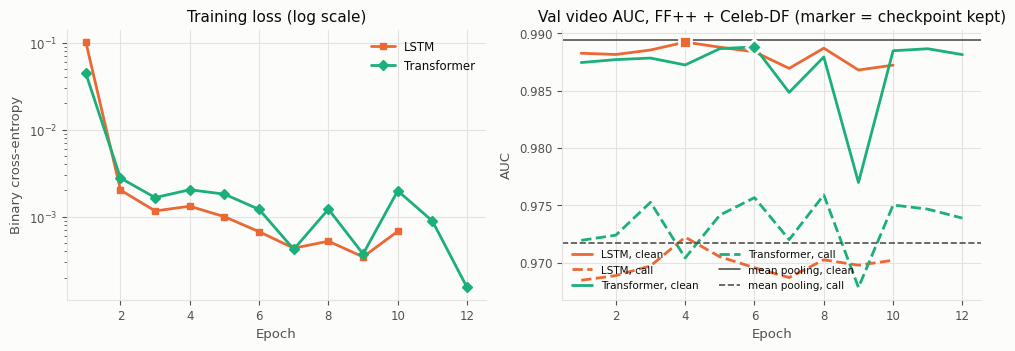

,epochs_run,best_epoch,train_loss_epoch_2,minutes_total
model,,,,
LSTM,10,4,0.0020,1.0700
Transformer,12,6,0.0028,1.2391


In [14]:
reference = {c: auc_of(videos[(videos.aggregator == "mean") & (videos.split == "val") & (videos.condition == c)])
             for c in ("clean", "call")}

fig, (ax_loss, ax_auc) = plt.subplots(1, 2, figsize=(10, 3.6))
summary = []
for agg_dir, agg in (("lstm", "LSTM"), ("transformer", "Transformer")):
    m = pd.read_csv(RUN_DIR / agg_dir / "metrics.csv")
    best = m.loc[m.val_video_auc_mean.idxmax()]
    summary.append(dict(model=agg, epochs_run=len(m), best_epoch=int(best.epoch),
                        train_loss_epoch_2=m.train_loss.iloc[1], minutes_total=m.minutes.sum()))
    ax_loss.plot(m.epoch, m.train_loss, color=COLOR[agg], marker=MARKER[agg], ms=5, label=agg)
    for condition, style in (("clean", "-"), ("call", "--")):
        ax_auc.plot(m.epoch, m[f"val_video_auc_{condition}"], style, color=COLOR[agg],
                    label=f"{agg}, {condition}")
    ax_auc.plot(best.epoch, best.val_video_auc_clean, MARKER[agg], ms=8, color=COLOR[agg], mec=SURFACE, mew=2, zorder=3)
for condition, style in (("clean", "-"), ("call", "--")):
    ax_auc.axhline(reference[condition], color=INK_2, lw=1.2, ls=style, label=f"mean pooling, {condition}")
ax_loss.set(yscale="log", title="Training loss (log scale)", xlabel="Epoch", ylabel="Binary cross-entropy")
ax_auc.set(title="Val video AUC, FF++ + Celeb-DF (marker = checkpoint kept)", xlabel="Epoch", ylabel="AUC")
ax_loss.legend()
ax_auc.legend(fontsize=7.5, ncol=2, loc="lower left")
fig.tight_layout()
plt.show()
pd.DataFrame(summary).set_index("model").round(4)

Training loss falls to about 0.002 by epoch 2, and val AUC is at its final level from epoch 1, never clearly above
mean pooling (grey). Each head trains in about a minute.

The other side of this is overconfidence. The histograms show val window scores on a log-odds axis, so the
regions near 0 and 1 are visible. The ViT is already very sure about most fakes, so with mean pooling the fake
windows also pile up at the right edge. What the heads change is the shape: they squeeze almost every window into
two narrow spikes at the limits of their output (about 3e-5 and 0.99997, log-odds ±10.5), and a few percent of
real windows land in the top spike, next to the fakes.

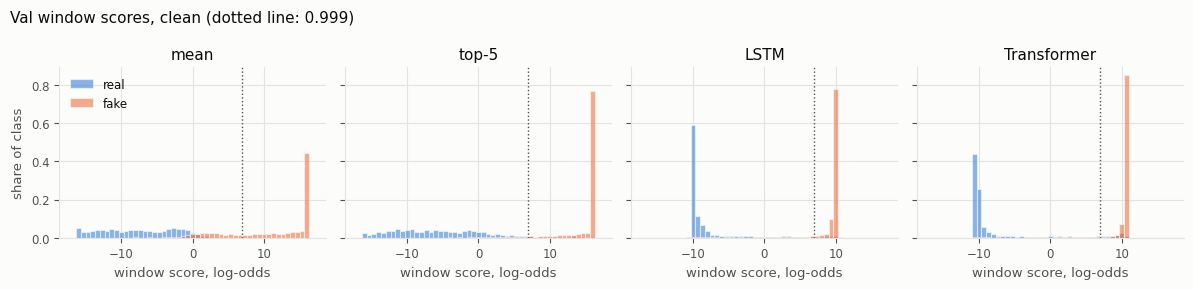

,real > 0.999,real > 0.9999,fake > 0.999,real < 0.001,highest score
aggregator,,,,,
mean,0.4%,0.0%,74.2%,53.8%,1.000000
top-5,4.4%,2.8%,93.8%,44.8%,1.000000
LSTM,3.1%,1.7%,92.3%,82.7%,0.999970
Transformer,7.7%,4.2%,95.4%,81.0%,0.999973


In [15]:
val = windows[(windows.split == "val") & (windows.condition == "clean")]
eps = 1e-7
logit = lambda p: np.log(np.clip(p, eps, 1 - eps) / (1 - np.clip(p, eps, 1 - eps)))
bins = np.linspace(-17, 17, 52)  # wider than the clip at ±16.1, so clipped scores land in the end bins

fig, axes = plt.subplots(1, 4, figsize=(12, 2.9), sharey=True)
shares = []
for ax, agg in zip(axes, AGGREGATORS.values()):
    w = val[val.aggregator == agg]
    for label, color, name in ((0, REAL, "real"), (1, FAKE, "fake")):
        s = logit(w.loc[w.label == label, "score"].to_numpy())
        # share of that class, so the 3:1 fake:real imbalance does not hide the reals
        ax.hist(s, bins, weights=np.full(len(s), 1 / len(s)), color=color, alpha=0.55, label=name,
                edgecolor=SURFACE, linewidth=0.8)
    ax.axvline(logit(0.999), color=INK_2, lw=1, ls=":")
    ax.set(title=agg, xlabel="window score, log-odds")
    real, fake = w[w.label == 0].score, w[w.label == 1].score
    shares.append({"aggregator": agg, "real > 0.999": (real > 0.999).mean(), "real > 0.9999": (real > 0.9999).mean(),
                   "fake > 0.999": (fake > 0.999).mean(), "real < 0.001": (real < 0.001).mean(),
                   "highest score": w.score.max()})
axes[0].set_ylabel("share of class")
axes[0].legend(loc="upper left")
fig.suptitle("Val window scores, clean (dotted line: 0.999)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()
(pd.DataFrame(shares).set_index("aggregator").style
 .format("{:.1%}").format("{:.6f}", subset=["highest score"]))

With mean pooling, 0.4% of real windows score above 0.999 and none above 0.9999. With the Transformer, 7.7% score
above 0.999 and 4.2% above 0.9999: confident mistakes in the same spike as the fakes. To keep false alarms at 1%, the
rule's threshold has to sit inside that spike (0.99993-0.99996, just under the heads' ceiling of about 0.99997),
which is why those rules are fragile. Top-5 has a milder form of the same problem: the highest frames of a real
window are its noisiest ones.

## 6. Conclusion and open points

**RQ2, so far: no.** Learned temporal aggregation does not beat averaging the frame scores. It ties in-domain, is
slightly worse on the unseen DFDC set, and gives a weaker alarm rule. **Mean pooling is the choice, made on val**:
tied AUC, best rule (most fakes caught at ≤1% false alarms), fastest alarm, and no training. A head costs about
1 ms per window against about 220 ms for the 32 ViT frames, so cost is not the argument; the lack of gain is.

**Before this goes in the report**

- **Call quality is provisional.** The `*_call` features were degraded with per-frame settings (flicker). Redo
  them with per-window settings, retrain the heads and rerun this notebook; the Transformer's call-quality edge is
  the one result that could change the conclusion.
- **One training seed per head.** The bootstrap resamples videos only.
- **DFDC is the unfiltered 400-video sample** (77 real). Audio-only fakes are still in it, and TPR at 1% FPR is not
  meaningful with 77 reals.
- **ViT as the base run.** If it was picked for its DFDC score, that is a choice made on test; say so in the report.
- **Which commit produced the run** is not recorded on the GPU machine (probably `origin/temporal` at 220f20a).

**Possible follow-up** (cheap, about a minute per head): train the heads on features the backbone was not
fitted to, for example cross-fitted on part of val, to test whether the near-separable training features are the
reason they add nothing.